In [1]:
import pandas as pd

In [2]:
df_population_raw = pd.read_csv('Population_total.csv')

In [3]:
df_population_raw

,country,year,population
0,China,2020.0,1.439324e+09
1,China,2019.0,1.433784e+09
2,China,2018.0,1.427648e+09
3,China,2017.0,1.421022e+09
4,China,2016.0,1.414049e+09
...,...,...,...
4180,United States,1965.0,1.997337e+08
4181,United States,1960.0,1.867206e+08
4182,United States,1955.0,1.716853e+08
4183,India,1960.0,4.505477e+08


# Making a Pivot Table

.pivot() returns reshaped DataFrame organised by given index / column values ("pivot without aggregation")

In [4]:
# droping null values
df_population_raw.dropna(inplace=True)

In [5]:
# making a pivot table 
df_pivot = df_population_raw.pivot(index='year', columns='country', values='population')

In [6]:
# selcting some countries
df_pivot = df_pivot[['United States', 'India', 'China', 'Indonesia', 'United Kingdom']]

In [7]:
df_pivot

country,United States,India,China,Indonesia,United Kingdom
year,,,,,
1955.0,171685336.0,4.098806e+08,6.122416e+08,77273425.0,51063902.0
1960.0,186720571.0,4.505477e+08,6.604081e+08,87751068.0,52370602.0
1965.0,199733676.0,4.991233e+08,7.242190e+08,100267062.0,54240850.0
1970.0,209513341.0,5.551898e+08,8.276014e+08,114793178.0,55573453.0
1975.0,219081251.0,6.231029e+08,9.262409e+08,130680727.0,56152333.0
1980.0,229476354.0,6.989528e+08,1.000089e+09,147447836.0,56209171.0
1985.0,240499825.0,7.843600e+08,1.075589e+09,164982451.0,56413553.0
1990.0,252120309.0,8.732778e+08,1.176884e+09,181413402.0,57134391.0
1995.0,265163745.0,9.639226e+08,1.240921e+09,196934260.0,57932453.0


# Data Visualistaions with Pandas

## Lineplot

<Axes: xlabel='year'>

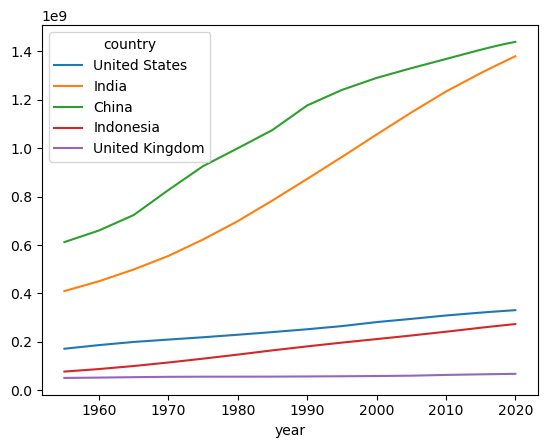

In [8]:
df_pivot.plot(kind='line')

<Axes: title={'center': 'Population (1955-2020)'}, xlabel='Year', ylabel='Population'>

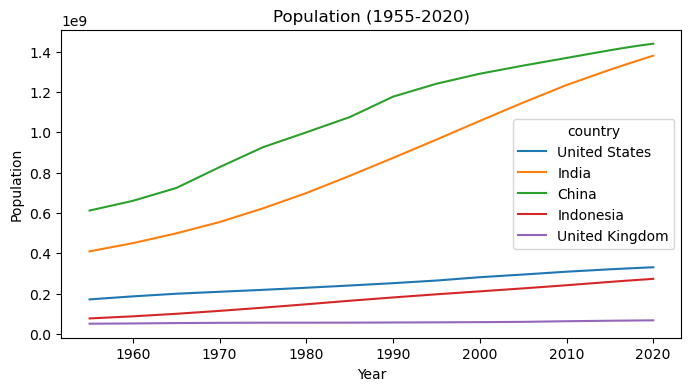

In [9]:
df_pivot.plot(kind='line', xlabel='Year', ylabel='Population', title='Population (1955-2020)', figsize=(8,4))

## Barplot

## Single barplot

In [10]:
# selecting only one year
df_pivot.index

Index([1955.0, 1960.0, 1965.0, 1970.0, 1975.0, 1980.0, 1985.0, 1990.0, 1995.0,
       2000.0, 2005.0, 2010.0, 2015.0, 2016.0, 2017.0, 2018.0, 2019.0, 2020.0],
      dtype='float64', name='year')

In [11]:
df_pivot_2020 = df_pivot[df_pivot.index.isin([2020])]

In [12]:
df_pivot_2020

country,United States,India,China,Indonesia,United Kingdom
year,,,,,
2020.0,331002651.0,1.380004e+09,1.439324e+09,273523615.0,67886011.0


In [13]:
# transpose dataframe from rows to columns and viceversa
df_pivot_2020 = df_pivot_2020.T

In [14]:
df_pivot_2020

year,2020.0
country,
United States,3.310027e+08
India,1.380004e+09
China,1.439324e+09
Indonesia,2.735236e+08
United Kingdom,6.788601e+07


<Axes: xlabel='country'>

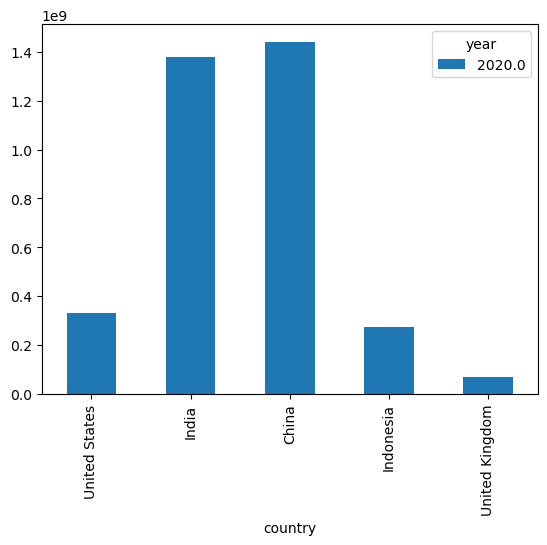

In [15]:
# making barplot
df_pivot_2020.plot(kind='bar')

<Axes: title={'center': 'Populations in 2020'}, xlabel='Year', ylabel='Population'>

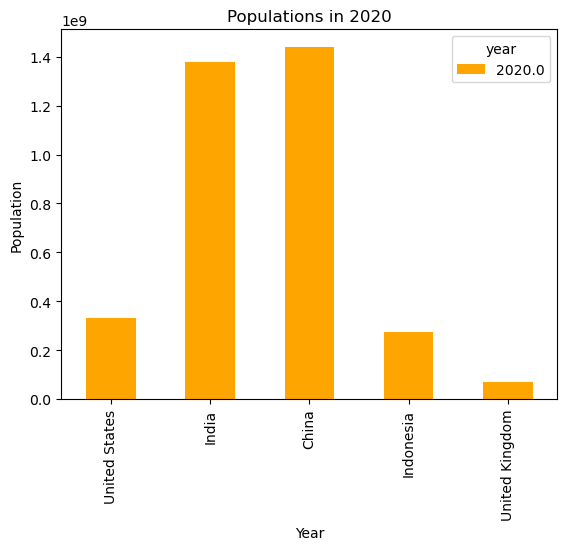

In [16]:
df_pivot_2020.plot(kind='bar', color='orange', xlabel='Year', ylabel='Population', title='Populations in 2020')

## Barplot grouped by 'n' variables

In [17]:
df_pivot_sample = df_pivot[df_pivot.index.isin([1980, 1990, 2000, 2010, 2020])]

In [18]:
df_pivot_sample

country,United States,India,China,Indonesia,United Kingdom
year,,,,,
1980.0,229476354.0,6.989528e+08,1.000089e+09,147447836.0,56209171.0
1990.0,252120309.0,8.732778e+08,1.176884e+09,181413402.0,57134391.0
2000.0,281710909.0,1.056576e+09,1.290551e+09,211513823.0,58923309.0
2010.0,309011475.0,1.234281e+09,1.368811e+09,241834215.0,63459808.0
2020.0,331002651.0,1.380004e+09,1.439324e+09,273523615.0,67886011.0


<Axes: xlabel='year'>

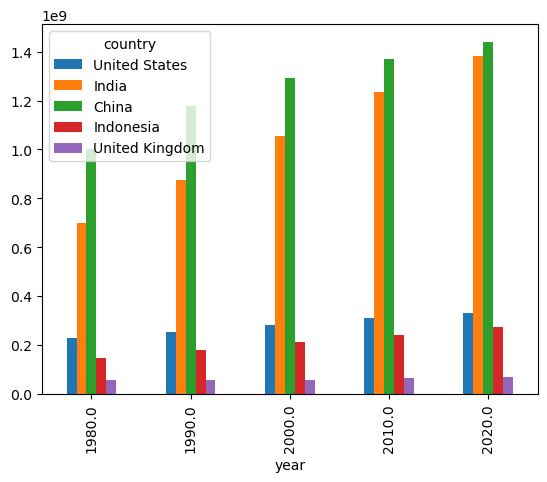

In [19]:
# making grouped barplot
df_pivot_sample.plot(kind='bar')

<Axes: title={'center': 'Populations (1980-2020)'}, xlabel='Year', ylabel='Population'>

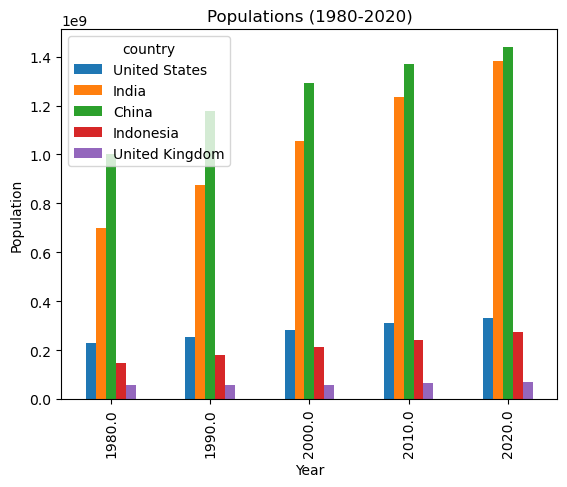

In [20]:
df_pivot_sample.plot(kind='bar', xlabel='Year', ylabel='Population', title='Populations (1980-2020)')

# Piechart

In [21]:
# changing the column name
df_pivot_2020.rename(columns={2020:'2020'}, inplace=True)

In [22]:
df_pivot_2020

year,2020
country,
United States,3.310027e+08
India,1.380004e+09
China,1.439324e+09
Indonesia,2.735236e+08
United Kingdom,6.788601e+07


<Axes: title={'center': 'Population in 2020(%)'}, ylabel='2020'>

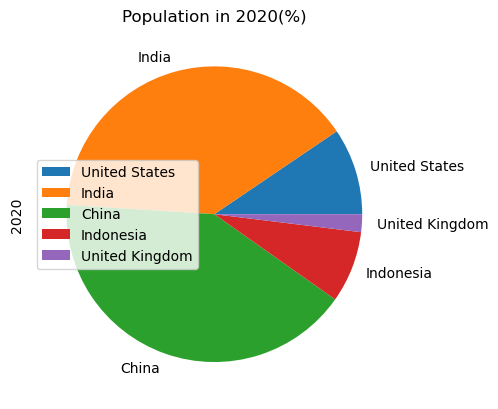

In [23]:
# making the plot
df_pivot_2020.plot(kind='pie', y='2020', title='Population in 2020(%)')

# Boxplot

## Single Boxplot

In [24]:
df_pivot

country,United States,India,China,Indonesia,United Kingdom
year,,,,,
1955.0,171685336.0,4.098806e+08,6.122416e+08,77273425.0,51063902.0
1960.0,186720571.0,4.505477e+08,6.604081e+08,87751068.0,52370602.0
1965.0,199733676.0,4.991233e+08,7.242190e+08,100267062.0,54240850.0
1970.0,209513341.0,5.551898e+08,8.276014e+08,114793178.0,55573453.0
1975.0,219081251.0,6.231029e+08,9.262409e+08,130680727.0,56152333.0
1980.0,229476354.0,6.989528e+08,1.000089e+09,147447836.0,56209171.0
1985.0,240499825.0,7.843600e+08,1.075589e+09,164982451.0,56413553.0
1990.0,252120309.0,8.732778e+08,1.176884e+09,181413402.0,57134391.0
1995.0,265163745.0,9.639226e+08,1.240921e+09,196934260.0,57932453.0


<Axes: ylabel='Population'>

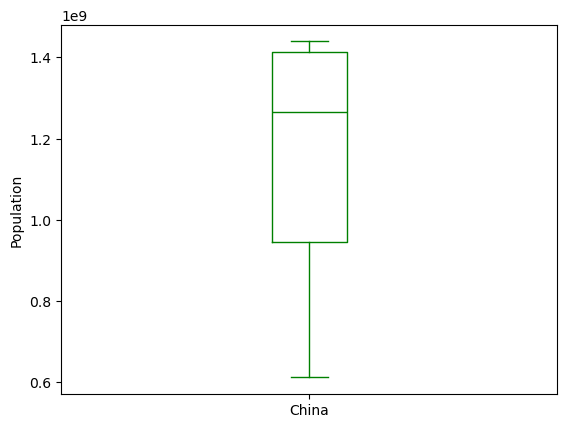

In [25]:
df_pivot['China'].plot(kind='box', color='green', ylabel='Population')

 ## Multiple boxplots

<Axes: ylabel='Population'>

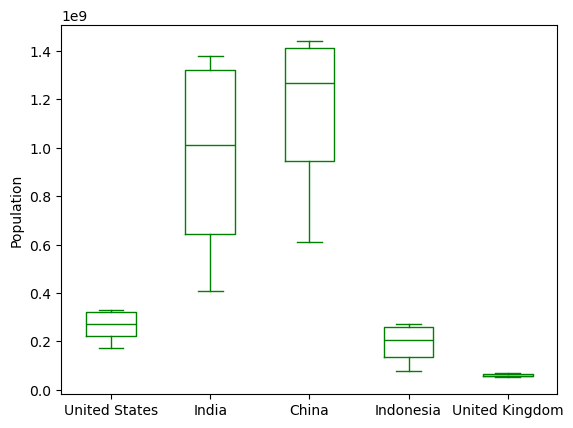

In [26]:
df_pivot.plot(kind='box', color='green', ylabel='Population')

# Histogram

<Axes: ylabel='Frequency'>

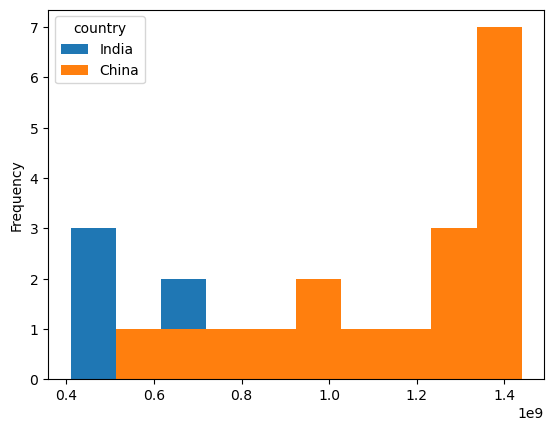

In [27]:
df_pivot[['India', 'China']].plot(kind='hist')

# Scatterplot

In [28]:
# selcting a sample of the raw data
df_sample = df_population_raw[df_population_raw['country'].isin(['United States', 'India', 'China', 'Indonesia', 'Brazil'])]

In [29]:
df_sample

,country,year,population
0,China,2020.0,1.439324e+09
1,China,2019.0,1.433784e+09
2,China,2018.0,1.427648e+09
3,China,2017.0,1.421022e+09
4,China,2016.0,1.414049e+09
...,...,...,...
4180,United States,1965.0,1.997337e+08
4181,United States,1960.0,1.867206e+08
4182,United States,1955.0,1.716853e+08
4183,India,1960.0,4.505477e+08


<Axes: xlabel='year', ylabel='population'>

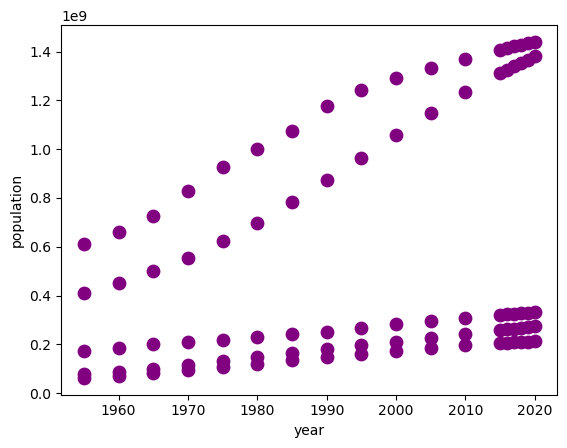

In [30]:
# creating the plot
df_sample.plot(kind='scatter', x='year', y='population', s=80, color='purple')

# Adding Matplotlib to Pandas

In [31]:
import matplotlib.pyplot as plt

## Lineplot

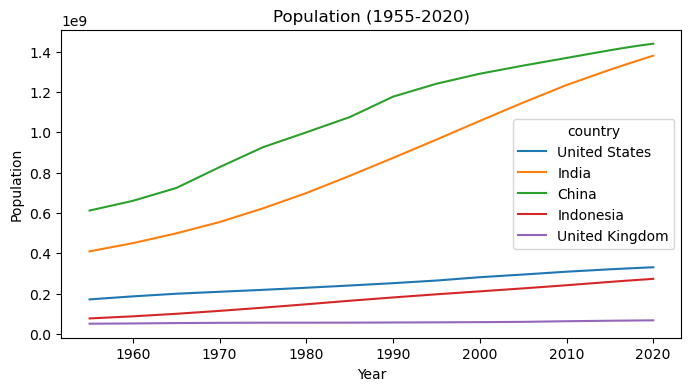

In [32]:
df_pivot.plot(kind='line', xlabel='Year', ylabel='Population', title='Population (1955-2020)', figsize=(8,4))
# save plot
plt.savefig('my_test.png')
# show plot 
plt.show()

In [33]:
# export dataframe to an excel file
df_pivot.to_excel('pivot_table.xlsx')

# Making interactive vizulaisations with pandas

In [34]:
#!pip install plotly

In [35]:
import pandas as pd
import plotly.express as px
from IPython.display import display, HTML

In [36]:
# reading the csv file
df_population_raw = pd.read_csv('population_total.csv')
# dropping null values
df_population_raw.dropna(inplace=True)
# making a pivot table
df_pivot = df_population_raw.pivot(index='year', columns='country', values='population')
# selecting some countries
df_pivot = df_pivot[['United States', 'India', 'China', 'Indonesia', 'Brazil']]
# showing pivot table
df_pivot

country,United States,India,China,Indonesia,Brazil
year,,,,,
1955.0,171685336.0,4.098806e+08,6.122416e+08,77273425.0,62533919.0
1960.0,186720571.0,4.505477e+08,6.604081e+08,87751068.0,72179226.0
1965.0,199733676.0,4.991233e+08,7.242190e+08,100267062.0,83373530.0
1970.0,209513341.0,5.551898e+08,8.276014e+08,114793178.0,95113265.0
1975.0,219081251.0,6.231029e+08,9.262409e+08,130680727.0,107216205.0
1980.0,229476354.0,6.989528e+08,1.000089e+09,147447836.0,120694009.0
1985.0,240499825.0,7.843600e+08,1.075589e+09,164982451.0,135274080.0
1990.0,252120309.0,8.732778e+08,1.176884e+09,181413402.0,149003223.0
1995.0,265163745.0,9.639226e+08,1.240921e+09,196934260.0,162019896.0


## Lineplot

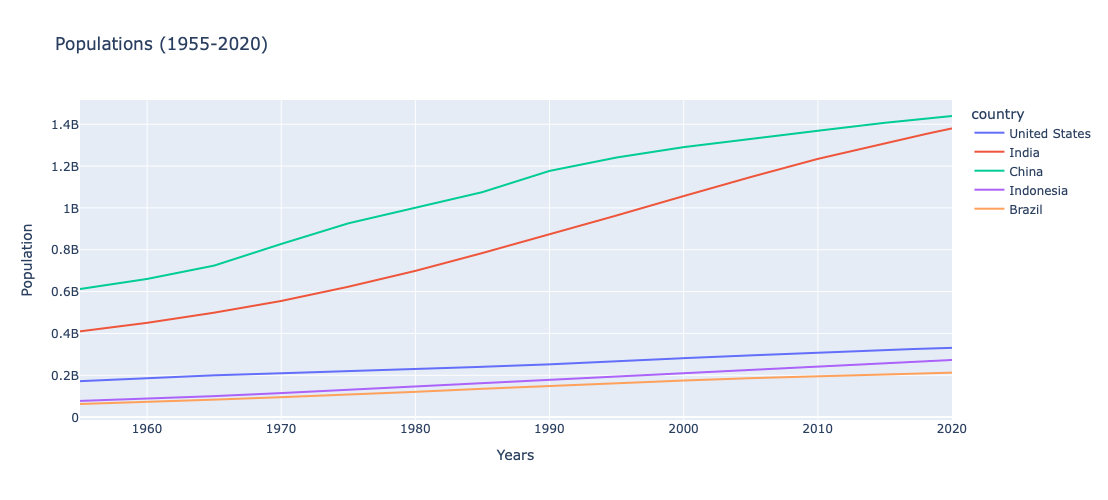

In [37]:
px.line(df_pivot, labels={'year':'Years', 'value':'Population'}, title='Populations (1955-2020)', width=1000, height=500)

## Barplot

In [38]:
# selecting only one year (2020)
df_pivot_2020 = df_pivot[df_pivot.index.isin([2020])]

In [39]:
# transpose dataframe from rows to columns and vise versa
df_pivot_2020 = df_pivot_2020.T

In [40]:
df_pivot_2020

year,2020.0
country,
United States,3.310027e+08
India,1.380004e+09
China,1.439324e+09
Indonesia,2.735236e+08
Brazil,2.125594e+08


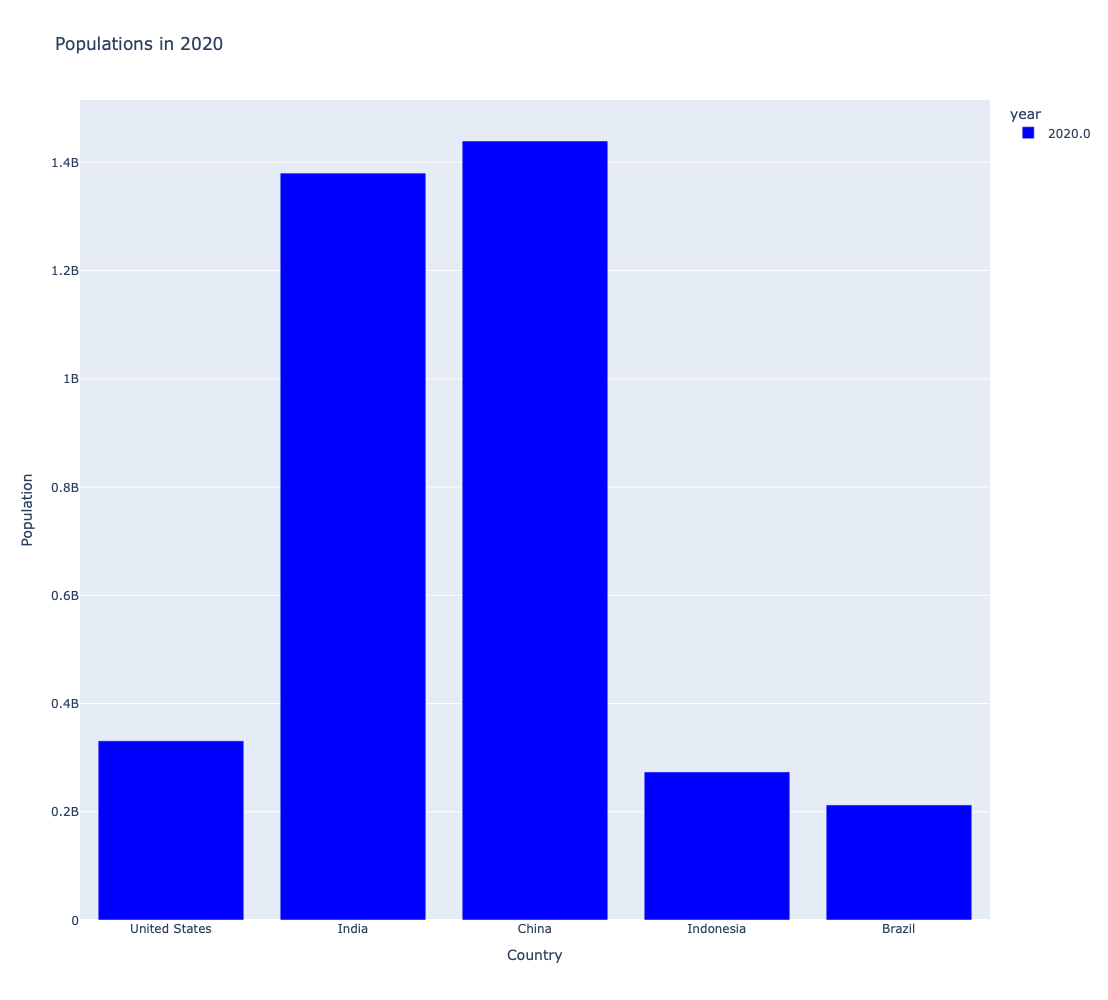

In [58]:
px.bar(df_pivot_2020, color_discrete_sequence=['blue'], labels={'country':'Country', 'value':'Population'}, title='Populations in 2020',
       height=1000, width=1000)

### Barplot grouped by 'n' variables

In [59]:
# selecting a few years
df_pivot_sample = df_pivot[df_pivot.index.isin([1980, 1990, 2000, 2010, 2020])]

In [61]:
df_pivot_sample

country,United States,India,China,Indonesia,Brazil
year,,,,,
1980.0,229476354.0,6.989528e+08,1.000089e+09,147447836.0,120694009.0
1990.0,252120309.0,8.732778e+08,1.176884e+09,181413402.0,149003223.0
2000.0,281710909.0,1.056576e+09,1.290551e+09,211513823.0,174790340.0
2010.0,309011475.0,1.234281e+09,1.368811e+09,241834215.0,195713635.0
2020.0,331002651.0,1.380004e+09,1.439324e+09,273523615.0,212559417.0


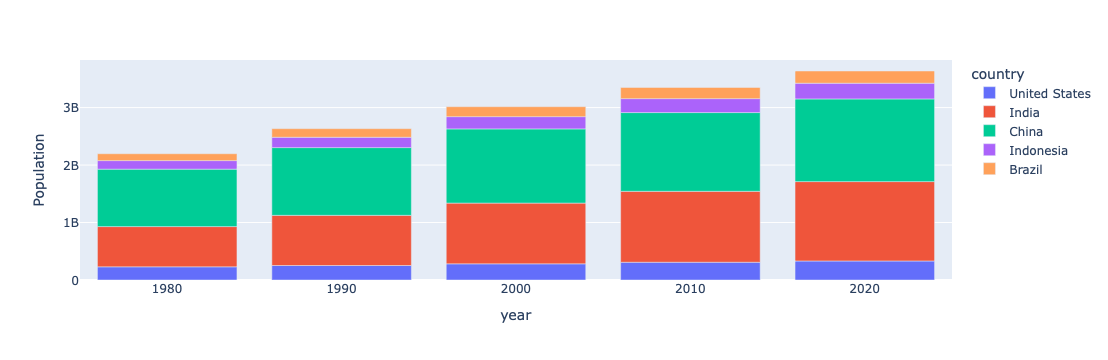

In [64]:
px.bar(df_pivot_sample, barmode='relative', labels={'value':'Population'})

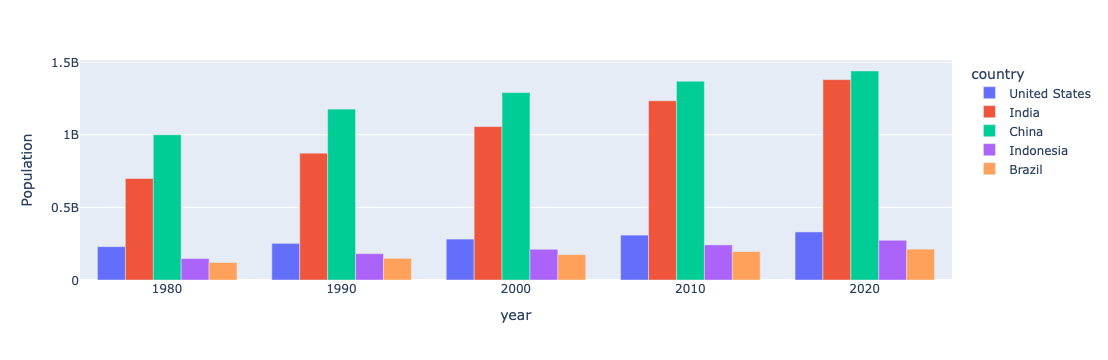

In [65]:
px.bar(df_pivot_sample, barmode='group', labels={'value':'Population'})

## Piechart

In [67]:
# chnaging column name
df_pivot_2020.rename(columns={2020:'2020'}, inplace=True)

In [70]:
df_pivot_2020

year,2020
country,
United States,3.310027e+08
India,1.380004e+09
China,1.439324e+09
Indonesia,2.735236e+08
Brazil,2.125594e+08


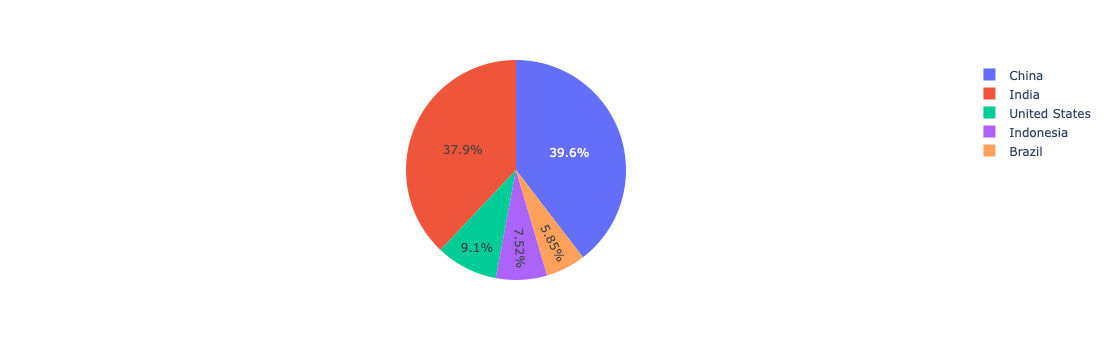

In [74]:
px.pie(df_pivot_2020, values='2020', names=df_pivot_2020.index)

## Boxplot

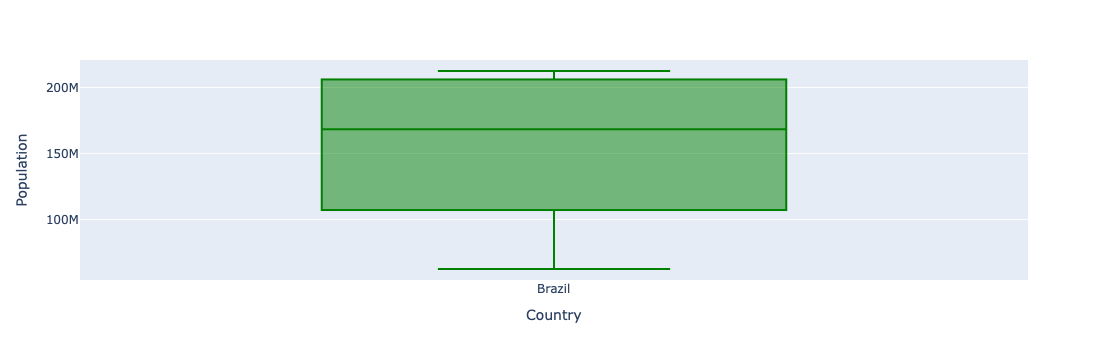

In [79]:
px.box(df_pivot['Brazil'], color_discrete_sequence=['green'], labels={'value':'Population', 'variable':'Country'})

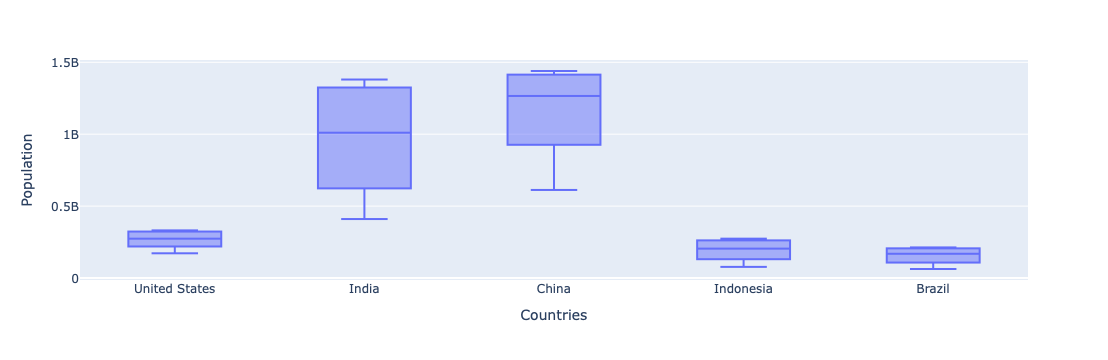

In [81]:
px.box(df_pivot, labels={'value':'Population', 'country':'Countries'})

## Histogram

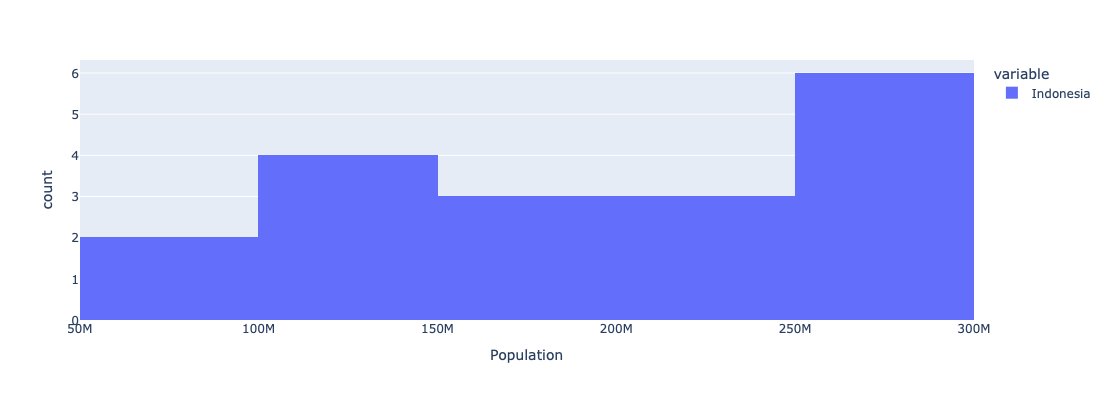

In [92]:
px.histogram(df_pivot['Indonesia'], nbins=5, labels={'value':'Population'}, height=400)

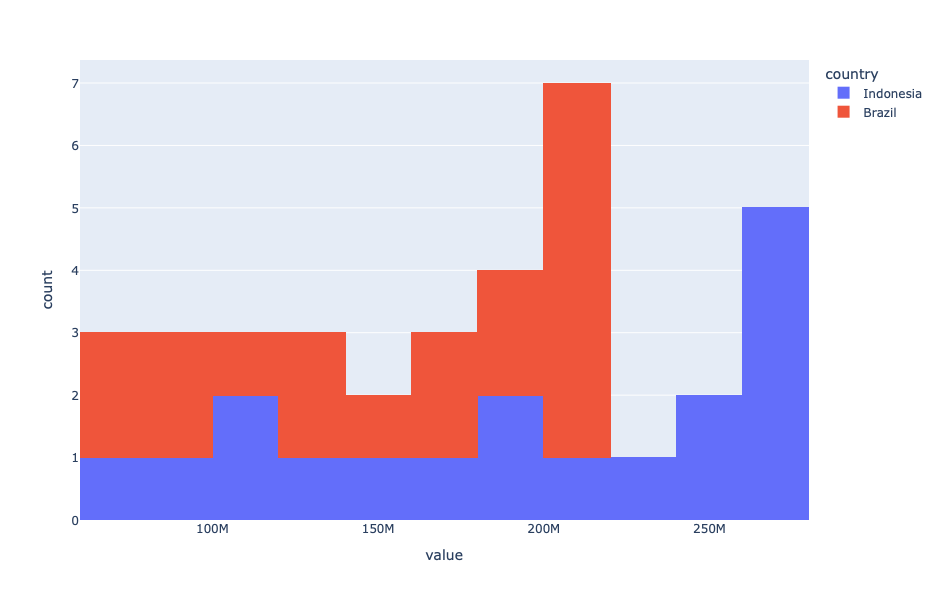

In [102]:
px.histogram(df_pivot[['Indonesia', 'Brazil']], height=600, nbins=12)

## Scatterplot

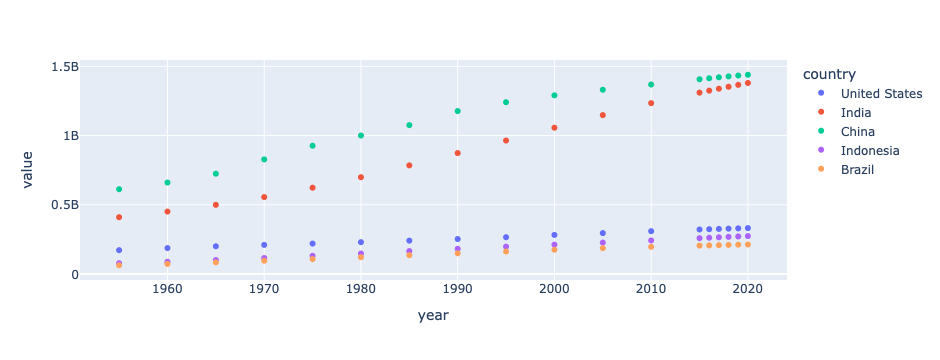

In [103]:
px.scatter(df_pivot)